# Scalar conservation in WV flux field: 
## W and curl(\<qV\>) : which is more conserved?

In [4]:
!ls /Users/bmapes/Box/VaporLakes/Data/Eafrica_QVfluxvectors_6h/

QVflux6h_EastAfrica_coast_2000.nc QVflux6h_EastAfrica_coast_2013.nc
QVflux6h_EastAfrica_coast_2001.nc QVflux6h_EastAfrica_coast_2014.nc
QVflux6h_EastAfrica_coast_2002.nc QVflux6h_EastAfrica_coast_2015.nc
QVflux6h_EastAfrica_coast_2003.nc QVflux6h_EastAfrica_coast_2016.nc
QVflux6h_EastAfrica_coast_2004.nc QVflux6h_EastAfrica_coast_2017.nc
QVflux6h_EastAfrica_coast_2005.nc QVflux6h_EastAfrica_coast_2018.nc
QVflux6h_EastAfrica_coast_2006.nc QVflux6h_EastAfrica_coast_2019.nc
QVflux6h_EastAfrica_coast_2007.nc QVflux6h_EastAfrica_coast_2020.nc
QVflux6h_EastAfrica_coast_2008.nc QVflux6h_EastAfrica_coast_2021.nc
QVflux6h_EastAfrica_coast_2009.nc QVflux6h_EastAfrica_coast_2022.nc
QVflux6h_EastAfrica_coast_2010.nc QVflux6h_EastAfrica_coast_2023.nc
QVflux6h_EastAfrica_coast_2011.nc QVflux6h_EastAfrica_coast_2024.nc
QVflux6h_EastAfrica_coast_2012.nc QVflux6h_EastAfrica_coast_2025.nc


In [19]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

tslice = slice("2017-05-10", "2017-05-20")

qv = xr.open_dataset("/Users/bmapes/Box/VaporLakes/Data/Eafrica_QVfluxvectors_6h/QVflux6h_EastAfrica_coast_2017.nc").sel(
        time=tslice)
pw = xr.open_dataset("/Users/bmapes/Box/VaporLakes/Data/Eafrica_TQV_6h_MERRA2/TQV6h_EastAfrica_coast_2017.nc").sel(
        time=tslice)

u, v = qv["UFLXQV"], qv["VFLXQV"]
qv['curl'] = (v.differentiate("lon") - u.differentiate("lat"))
qv['PW'] = pw.TQV 

qv

<xarray.Dataset> Size: 2MB
Dimensions:  (lon: 39, lat: 81, time: 44)
Coordinates:
  * lon      (lon) float64 312B 28.12 28.75 29.38 30.0 ... 50.62 51.25 51.88
  * lat      (lat) float64 648B -20.0 -19.5 -19.0 -18.5 ... 18.5 19.0 19.5 20.0
  * time     (time) datetime64[ns] 352B 2017-05-10T00:30:00 ... 2017-05-20T18...
Data variables:
    UFLXQV   (time, lat, lon) float32 556kB -76.96 -77.29 ... -33.97 -28.97
    VFLXQV   (time, lat, lon) float32 556kB 43.64 44.56 44.1 ... -121.3 -133.6
    curl     (time, lat, lon) float32 556kB -12.51 -24.59 -32.6 ... -57.25 -57.1
    PW       (time, lat, lon) float32 556kB nan nan nan nan ... nan nan nan nan
Attributes:
    long_name:       eastward_flux_of_atmospheric_water_vapor
    units:           kg m-1 s-1
    fmissing_value:  1000000000000000.0
    standard_name:   eastward_flux_of_atmospheric_water_vapor
    vmax:            1000000000000000.0
    vmin:            -1000000000000000.0
    valid_range:     [-1.e+15  1.e+15]
    _ChunkSizes:     [  1  91 144]

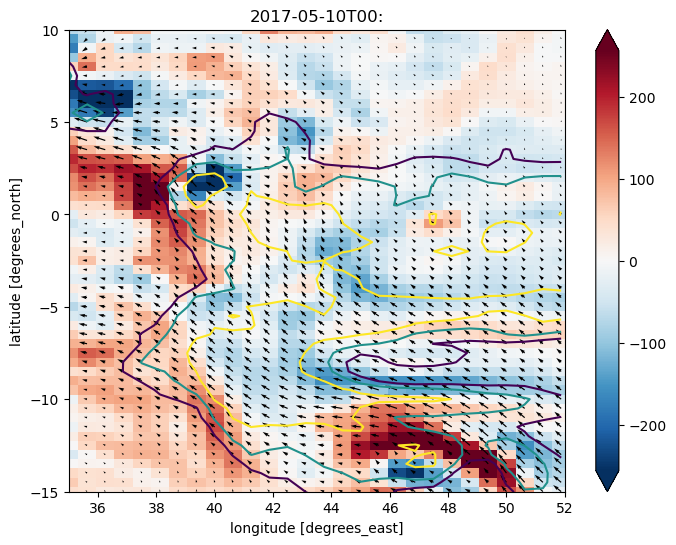

In [20]:
# color scale fixed across all frames
clim = float(abs(curl).quantile(0.99))
s = 1  # quiver stride

fig, ax = plt.subplots(figsize=(8, 6))
im = curl.isel(time=0).plot.pcolormesh(ax=ax, cmap="RdBu_r",
                                        vmin=-clim, vmax=clim,
                                        add_colorbar=True)

def draw(t):
    ax.clear()
    curl.sel(time=t).plot.pcolormesh(ax=ax, cmap="RdBu_r",
                                      vmin=-clim, vmax=clim,
                                      add_colorbar=False)
    ax.quiver(u.lon[::s], u.lat[::s],
              u.sel(time=t).values[::s, ::s],
              v.sel(time=t).values[::s, ::s])
    ax.contour(pw.lon, pw.lat, pw["TQV"].sel(time=t, method='nearest'),
               levels=[45,50,55]) #, colors="black", linewidths=1.5)
    ax.set_xlim([35,52])
    ax.set_ylim([-15,10])
    
    ax.set_title(str(t)[:14])

ani = animation.FuncAnimation(fig, draw, frames=qv.time.values, interval=500)

from IPython.display import HTML
HTML(ani.to_jshtml())

#ani.save("/Users/bmapes/Box/VaporLakes/qvflux_animation.gif", writer="pillow", dpi=80)

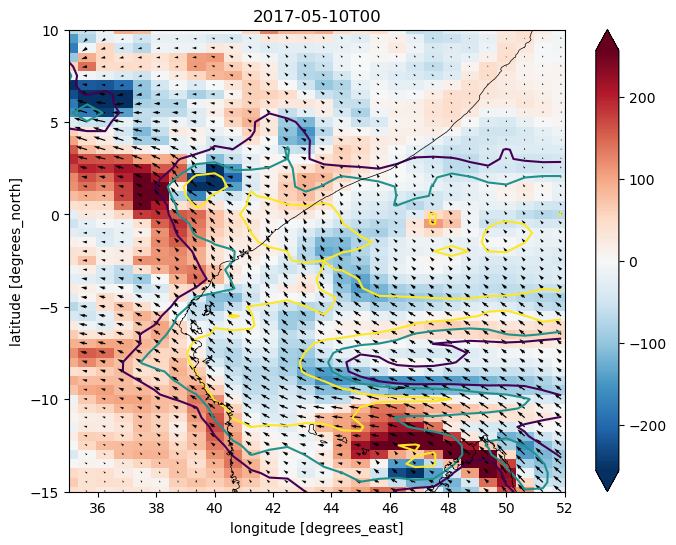

In [22]:
# Supposedly with coastlines 

import cartopy.io.shapereader as shpreader
from shapely.ops import unary_union
#coast_shp = shpreader.natural_earth(resolution="10m", category="physical", name="coastline") # SLOW read at 10m res.
coast_geom = unary_union([g for g in shpreader.Reader(coast_shp).geometries()])

# color scale fixed across all frames
clim = float(abs(curl).quantile(0.99))
s = 1  # quiver stride

fig, ax = plt.subplots(figsize=(8, 6))
im = curl.isel(time=0).plot.pcolormesh(ax=ax, cmap="RdBu_r",
                                        vmin=-clim, vmax=clim,
                                        add_colorbar=True)

def draw(t):
    ax.clear()
    curl.sel(time=t).plot.pcolormesh(ax=ax, cmap="RdBu_r",
                                      vmin=-clim, vmax=clim,
                                      add_colorbar=False)
    ax.quiver(u.lon[::s], u.lat[::s],
              u.sel(time=t).values[::s, ::s],
              v.sel(time=t).values[::s, ::s])
    ax.contour(pw.lon, pw.lat, pw["TQV"].sel(time=t, method="nearest"),
               levels=[45,50,55]) #, colors="black", linewidths=1.5)
    for geom in coast_geom.geoms:
        ax.plot(*geom.xy, color="black", linewidth=0.5)
        
    ax.set(xlim=[35,52], ylim=[-15, 10], title=str(t)[:13])

ani = animation.FuncAnimation(fig, draw, frames=qv.time.values, interval=500)

from IPython.display import HTML
HTML(ani.to_jshtml())

#ani.save("/Users/bmapes/Box/VaporLakes/qvflux_animation.gif", writer="pillow", dpi=80)

In [25]:
qv

<xarray.Dataset> Size: 2MB
Dimensions:  (lon: 39, lat: 81, time: 44)
Coordinates:
  * lon      (lon) float64 312B 28.12 28.75 29.38 30.0 ... 50.62 51.25 51.88
  * lat      (lat) float64 648B -20.0 -19.5 -19.0 -18.5 ... 18.5 19.0 19.5 20.0
  * time     (time) datetime64[ns] 352B 2017-05-10T00:30:00 ... 2017-05-20T18...
Data variables:
    UFLXQV   (time, lat, lon) float32 556kB -76.96 -77.29 ... -33.97 -28.97
    VFLXQV   (time, lat, lon) float32 556kB 43.64 44.56 44.1 ... -121.3 -133.6
    curl     (time, lat, lon) float32 556kB -12.51 -24.59 -32.6 ... -57.25 -57.1
    PW       (time, lat, lon) float32 556kB nan nan nan nan ... nan nan nan nan
Attributes:
    long_name:       eastward_flux_of_atmospheric_water_vapor
    units:           kg m-1 s-1
    fmissing_value:  1000000000000000.0
    standard_name:   eastward_flux_of_atmospheric_water_vapor
    vmax:            1000000000000000.0
    vmin:            -1000000000000000.0
    valid_range:     [-1.e+15  1.e+15]
    _ChunkSizes:     [  1  91 144]